# Diffusion model on MNIST and Fashion-MNIST

In this notebook, I train a small diffusion model on the same datasets used for the VAE. Instead of compressing an image into a latent vector, the model learns to predict noise added at different timesteps. I first check the forward process, then train the noise predictor and generate images by reversing the process.

I use the saved training and validation splits from the data exploration notebook. I leave the official test sets aside.

## 1. Setup

In [2]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import MNIST, FashionMNIST
from torchvision.transforms import ToTensor
from IPython.display import display

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents]
             if (p / "src/diffusion.py").is_file() and (p / "data/splits").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from the project root or notebooks/ directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.diffusion import DDPM, NoiseUNet
from src.diffusion_training import fit_diffusion, load_diffusion
from src.training import set_seed

SEED = 111
set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

Device: cuda
NVIDIA GeForce RTX 3050 Laptop GPU


## 2. Experiment settings

I start with a small run to check that the training and saving code works. Once that is finished, I can set `SMOKE_TEST=False` to train on the full splits. I keep the architecture and diffusion schedule the same for both datasets.

Sampling requires one network evaluation per reverse timestep, so it can take longer than generating images with the VAE.

In [3]:
SMOKE_TEST = False
REUSE_COMPLETED = True
RUN_TAG = "baseline_v1"
DATASET_NAMES = ["mnist", "fashion_mnist"]
BATCH_SIZE = 64
NUM_WORKERS = 0
BASE_CHANNELS = 32
TIMESTEPS = 300
LEARNING_RATE = 1e-3
EPOCHS = 2 if SMOKE_TEST else 30

MODE = "smoke" if SMOKE_TEST else "full"
FIG_DIR = ROOT / "results/figures/diffusion" / f"{RUN_TAG}_{MODE}"
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 3. Load the saved splits

As in the VAE notebook, `ToTensor()` scales the images to $[0,1]$. The diffusion training function later maps them to $[-1,1]$. I reuse the same indices so the comparison is based on the same training and validation examples.

In [4]:
data = {}
for name in DATASET_NAMES:
    dataset_class = {"mnist": MNIST, "fashion_mnist": FashionMNIST}[name]
    dataset = dataset_class(ROOT / "data/raw", train=True, download=False, transform=ToTensor())
    split_path = ROOT / "data/splits" / f"{name}_seed{SEED}.npz"
    with np.load(split_path, allow_pickle=False) as saved:
        train_idx, val_idx = saved["train_idx"].copy(), saved["val_idx"].copy()
    assert len(train_idx) == 50000 and len(val_idx) == 10000
    if SMOKE_TEST:
        rng = np.random.default_rng(SEED)
        train_idx = rng.choice(train_idx, 2048, replace=False)
        val_idx = rng.choice(val_idx, 512, replace=False)
    data[name] = (dataset, train_idx, val_idx)
    print(f"{name}: {len(train_idx):,} training / {len(val_idx):,} validation")

def make_loaders(name):
    dataset, train_idx, val_idx = data[name]
    train_loader = DataLoader(Subset(dataset, train_idx.tolist()), batch_size=BATCH_SIZE,
        shuffle=True, num_workers=NUM_WORKERS,
        generator=torch.Generator().manual_seed(SEED), pin_memory=device.type == "cuda")
    val_loader = DataLoader(Subset(dataset, val_idx.tolist()), batch_size=BATCH_SIZE,
        shuffle=False, num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")
    return train_loader, val_loader

mnist: 50,000 training / 10,000 validation
fashion_mnist: 50,000 training / 10,000 validation


## 4. Forward diffusion

At timestep $t$, I can obtain a noisy image directly from the original image:

$$x_t=\sqrt{\bar\alpha_t}\,x_0+\sqrt{1-\bar\alpha_t}\,\epsilon,\qquad \epsilon\sim\mathcal N(0,I).$$

Here $\bar\alpha_t$ is the product of the noise schedule's $\alpha$ values up to timestep $t$. As $t$ increases, the original image becomes harder to recognize. I use the same noise realization for each example in this plot so I can see how the image changes across timesteps.

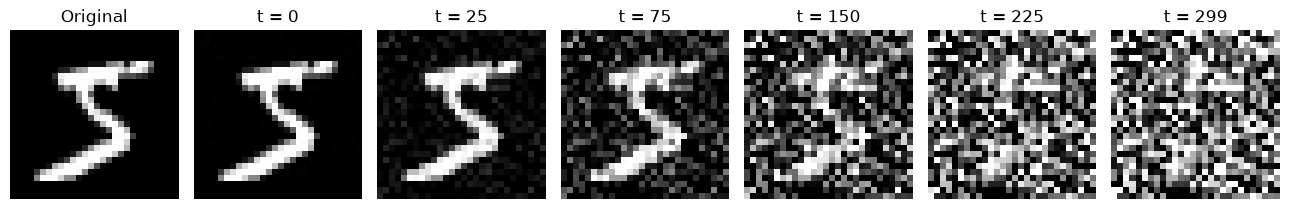

In [5]:
process = DDPM(timesteps=TIMESTEPS).to(device)
example = data["mnist"][0][0][0].unsqueeze(0).to(device) * 2 - 1
steps = [0, 25, 75, 150, 225, TIMESTEPS - 1]
noise = torch.randn(example.shape, device=device, generator=torch.Generator(device=device).manual_seed(SEED))
fig, axes = plt.subplots(1, len(steps) + 1, figsize=(13, 2.2))
axes[0].imshow(((example[0, 0] + 1) / 2).cpu(), cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original")
for ax, step in zip(axes[1:], steps):
    t = torch.tensor([step], device=device)
    xt, _ = process.add_noise(example, t, noise=noise)
    ax.imshow(((xt[0, 0].clamp(-1, 1) + 1) / 2).cpu(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"t = {step}")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Noise predictor and training objective

The U-Net takes a noisy image and its timestep and predicts the noise that was added. The timestep is encoded and passed into the convolutional blocks, so the model can respond differently to lightly and heavily corrupted images.

I train it with the mean squared error between the true and predicted noise:

$$\mathcal L=\mathbb E_{x_0,t,\epsilon}\left[\|\epsilon-\epsilon_\theta(x_t,t)\|_2^2\right].$$

The network does not receive class labels. This is an unconditional generation experiment.

In [6]:
model = NoiseUNet(base_channels=BASE_CHANNELS).to(device)
x = torch.randn(4, 1, 28, 28, device=device)
t = torch.tensor([0, 10, 100, TIMESTEPS - 1], device=device)
with torch.no_grad():
    prediction = model(x, t)
    test_loss = process.loss(model, x)
assert prediction.shape == x.shape
assert torch.isfinite(test_loss)
print("Output shape:", tuple(prediction.shape))
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("Initial noise-prediction loss:", round(test_loss.item(), 4))

Output shape: (4, 1, 28, 28)
Parameters: 267361
Initial noise-prediction loss: 1.1065


## 6. Train the models

I train one model per dataset with Adam and save the checkpoint with the lowest validation loss. Validation uses a fixed random seed each epoch to reduce variation from the sampled timesteps and noise.

A lower noise-prediction loss is useful, but it does not guarantee that generated images will look better. I will inspect samples after training as well.

In [7]:
runs = {}
for name in DATASET_NAMES:
    run_id = f"{name}_{RUN_TAG}_{MODE}"
    checkpoint_dir = ROOT / "results/checkpoints/diffusion" / run_id
    metric_dir = ROOT / "results/metrics/diffusion" / run_id
    config = dict(run_id=run_id, dataset=name, seed=SEED, timesteps=TIMESTEPS,
                  base_channels=BASE_CHANNELS, batch_size=BATCH_SIZE,
                  learning_rate=LEARNING_RATE, epochs=EPOCHS, mode=MODE)
    best_path = checkpoint_dir / "best.pt"
    if REUSE_COMPLETED and best_path.exists() and (metric_dir / "summary.json").exists():
        old_config = json.loads((metric_dir / "config.json").read_text())
        if old_config != config:
            raise ValueError(f"Existing configuration differs for {run_id}; choose a new RUN_TAG")
        model, process, saved = load_diffusion(best_path, device)
        history = pd.read_csv(metric_dir / "history.csv")
        summary = json.loads((metric_dir / "summary.json").read_text())
        print(f"Loaded {run_id} (best epoch {summary['best_epoch']})")
    else:
        set_seed(SEED)
        model = NoiseUNet(base_channels=BASE_CHANNELS)
        process = DDPM(timesteps=TIMESTEPS)
        train_loader, val_loader = make_loaders(name)
        history, summary = fit_diffusion(model, process, train_loader, val_loader,
                                         device, config, checkpoint_dir, metric_dir)
        model, process, saved = load_diffusion(best_path, device)
    runs[name] = dict(model=model, process=process, history=history, summary=summary)

display(pd.DataFrame([{"dataset": name, **r["summary"]} for name, r in runs.items()]))

mnist_baseline_v1_full:   3%|▎         | 1/30 [00:18<08:58, 18.56s/it]

Epoch 01: train=0.0754, val=0.0527


mnist_baseline_v1_full:   7%|▋         | 2/30 [00:36<08:24, 18.01s/it]

Epoch 02: train=0.0510, val=0.0501


mnist_baseline_v1_full:  10%|█         | 3/30 [00:53<07:56, 17.64s/it]

...

fashion_mnist_baseline_v1_full:  97%|█████████▋| 29/30 [08:53<00:18, 18.84s/it]

Epoch 29: train=0.0693, val=0.0698


fashion_mnist_baseline_v1_full: 100%|██████████| 30/30 [09:12<00:00, 18.41s/it]

Epoch 30: train=0.0699, val=0.0693


,dataset,best_epoch,best_val_loss,parameter_count
0,mnist,30,0.039733,267361
1,fashion_mnist,30,0.069329,267361


## 7. Training curves

I plot the training and validation losses to check whether the noise predictor continues improving. Since the training objective is sampled at random timesteps, small fluctuations are expected.

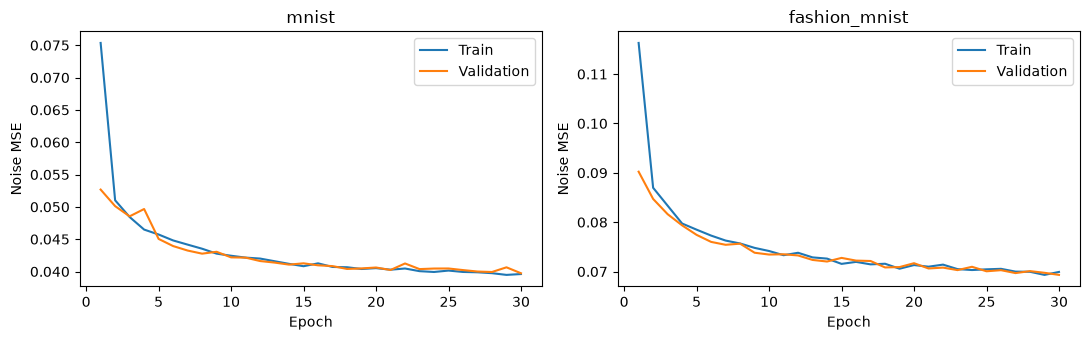

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (name, run) in zip(axes, runs.items()):
    h = run["history"]
    ax.plot(h["epoch"], h["train_loss"], label="Train")
    ax.plot(h["epoch"], h["val_loss"], label="Validation")
    ax.set(title=name, xlabel="Epoch", ylabel="Noise MSE")
    ax.legend()
plt.tight_layout()
plt.show()

## 8. Generate images

To generate an image, I start from Gaussian noise and repeatedly apply the learned reverse diffusion step. This is different from VAE sampling: the diffusion model needs many successive predictions to produce one image.

I show the generated samples without selecting only the best-looking examples.

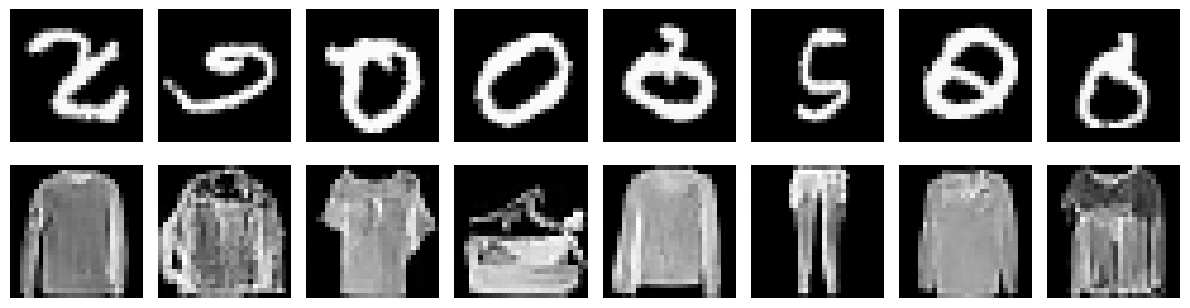

In [12]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for row, (name, run) in enumerate(runs.items()):
    set_seed(SEED + 10)
    samples = run["process"].sample(run["model"], count=8, device=device).cpu()
    for col, ax in enumerate(axes[row]):
        ax.imshow(samples[col, 0], cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
    axes[row, 0].set_ylabel(name, rotation=90)
plt.tight_layout()
plt.show()

## 9. Results and discussion

After running the full experiments, I will compare the validation curves and the generated images. I am particularly interested in whether the model produces recognizable digits and clothing items, whether samples are varied, and how generation compares with the VAE.

The diffusion loss measures noise prediction, while the VAE objective combines reconstruction and KL terms. Their numerical values should **not** be compared directly. For now, I will use the images and training behavior to make a qualitative comparison, and avoid drawing conclusions from the short smoke test.